# Forecasting PM2.5 24 hours ahead
**Question:** Can we predict Delhi's PM2.5 a day ahead better than simple rules?

**Setup:** for every hour *t*, predict PM2.5 at *t* using only information that was available 24 hours earlier. Models are compared against two simple baselines on a **time-based** split (train on the earlier 80%, test on the latest 20%), so the test never looks like the future leaking into the past.

In [1]:
import os

import numpy as np
import pandas as pd
import psycopg2
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

load_dotenv()

True

## 1. Load the data from Postgres

In [2]:
def load_data():
    conn = psycopg2.connect(os.environ["DATABASE_URL"])
    try:
        with conn.cursor() as cur:
            cur.execute(
                "SELECT time, pm2_5, temperature_2m, relative_humidity_2m, wind_speed_10m "
                "FROM delhi_air_weather ORDER BY time"
            )
            columns = [d[0] for d in cur.description]
            rows = cur.fetchall()
    finally:
        conn.close()
    return pd.DataFrame(rows, columns=columns)

raw = load_data()
print(raw.shape, raw["time"].min(), "->", raw["time"].max())

(1467, 5) 2026-09-13 00:00:00 -> 2026-11-13 02:00:00


## 2. Build features
Every feature is shifted back by 24 hours, so a row only uses information that existed a day before the hour it predicts. Missing hours become NaN and rows without a full set of features are dropped.

In [3]:
df = raw.set_index("time").sort_index().asfreq("h")  # one row per hour, gaps become NaN

HORIZON = 24
weather_cols = ["temperature_2m", "relative_humidity_2m", "wind_speed_10m"]

feat = pd.DataFrame(index=df.index)
feat["target"] = df["pm2_5"]
feat["pm25_lag24"] = df["pm2_5"].shift(HORIZON)
feat["pm25_lag48"] = df["pm2_5"].shift(HORIZON + 24)
feat["pm25_mean_prev24"] = df["pm2_5"].shift(HORIZON).rolling(24).mean()
for col in weather_cols:
    feat[col + "_lag24"] = df[col].shift(HORIZON)
feat["hour_sin"] = np.sin(2 * np.pi * feat.index.hour / 24)
feat["hour_cos"] = np.cos(2 * np.pi * feat.index.hour / 24)

before = len(feat)
feat = feat.dropna()
print(f"Usable rows: {len(feat)} of {before}")
feat.head()

Usable rows: 1419 of 1467


,target,pm25_lag24,pm25_lag48,pm25_mean_prev24,temperature_2m_lag24,relative_humidity_2m_lag24,wind_speed_10m_lag24,hour_sin,hour_cos
time,,,,,,,,,
2026-09-15 00:00:00,53.6,23.1,36.4,27.150000,27.7,85.0,9.4,0.000000,1.000000
2026-09-15 01:00:00,52.6,21.0,34.0,26.608333,27.3,88.0,9.4,0.258819,0.965926
2026-09-15 02:00:00,51.2,19.2,31.7,26.087500,26.9,90.0,9.2,0.500000,0.866025
2026-09-15 03:00:00,49.4,18.2,29.6,25.612500,26.7,91.0,9.4,0.707107,0.707107
2026-09-15 04:00:00,47.7,18.0,28.0,25.195833,26.1,93.0,9.0,0.866025,0.500000


## 3. Time-based train/test split (no shuffling)

In [4]:
cut = int(len(feat) * 0.8)
train, test = feat.iloc[:cut], feat.iloc[cut:]

X_cols = [c for c in feat.columns if c != "target"]
X_train, y_train = train[X_cols], train["target"]
X_test, y_test = test[X_cols], test["target"]

print("Train:", train.index.min(), "->", train.index.max(), len(train))
print("Test: ", test.index.min(), "->", test.index.max(), len(test))

Train: 2026-09-15 00:00:00 -> 2026-11-01 06:00:00 1135
Test:  2026-11-01 07:00:00 -> 2026-11-13 02:00:00 284


## 4. Baselines to beat
1. **Persistence:** predict the value from the same hour yesterday.
2. **Hourly average:** predict the average PM2.5 for that hour of day, learned on the training period only.

In [9]:
def scores(name, y_true, y_pred):
    return {
        "model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
    }

results = []

# Baseline 1: same hour yesterday
results.append(scores("Baseline: same hour yesterday", y_test, test["pm25_lag24"]))

# Baseline 2: average PM2.5 for that hour of day, from training data only
hourly_profile = train["target"].groupby(train.index.hour).mean()
hourly_pred = pd.Series(test.index.hour, index=test.index).map(hourly_profile)
results.append(scores("Baseline: hourly average", y_test, hourly_pred))

## 5. Models

In [6]:
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)
results.append(scores("Ridge regression", y_test, ridge_pred))

gbm = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200, random_state=42)
gbm.fit(X_train, y_train)
gbm_pred = gbm.predict(X_test)
results.append(scores("Gradient boosting", y_test, gbm_pred))

table = pd.DataFrame(results).round(1).set_index("model")
table

,MAE,RMSE
model,,
Baseline: same hour yesterday,25.3,32.1
Baseline: hourly average,55.5,65.3
Ridge regression,37.9,46.7
Gradient boosting,56.1,70.4


## 6. Compare
Lower is better for both MAE (average miss, in µg/m³) and RMSE (punishes big misses more). A model only earns its place if it beats **both** baselines on the test period.

In [7]:
best_baseline = table.loc[table.index.str.startswith("Baseline"), "MAE"].min()
for name in ["Ridge regression", "Gradient boosting"]:
    change = (table.loc[name, "MAE"] - best_baseline) / best_baseline
    print(f"{name}: MAE {table.loc[name, 'MAE']} vs best baseline {best_baseline}  ({change:+.0%})")

Ridge regression: MAE 37.9 vs best baseline 25.3  (+50%)
Gradient boosting: MAE 56.1 vs best baseline 25.3  (+122%)


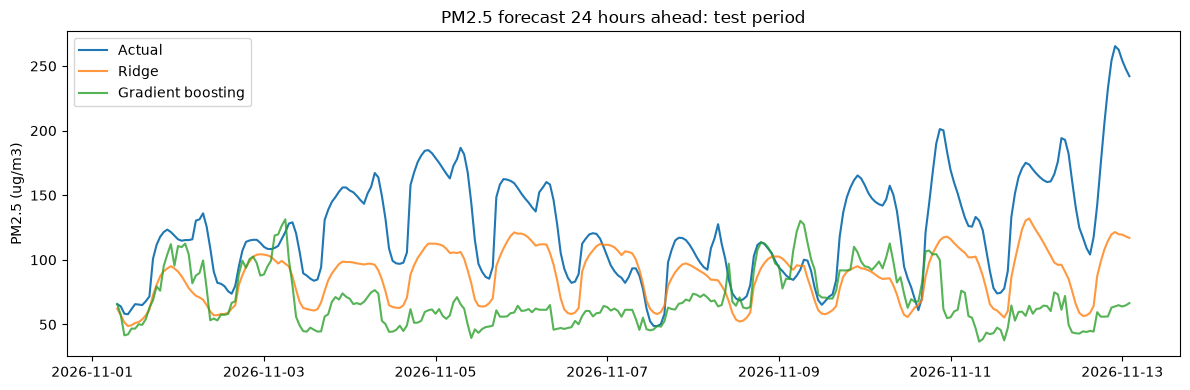

In [8]:
plt.figure(figsize=(12, 4))
plt.plot(y_test.index, y_test, label="Actual", linewidth=1.5)
plt.plot(y_test.index, ridge_pred, label="Ridge", alpha=0.8)
plt.plot(y_test.index, gbm_pred, label="Gradient boosting", alpha=0.8)
plt.title("PM2.5 forecast 24 hours ahead: test period")
plt.ylabel("PM2.5 (ug/m3)")
plt.legend()
plt.tight_layout()
plt.show()

## 7. What to write down (fill in)
- **Best model and its MAE versus the baselines:**
- **Did any model beat both baselines? By how much?**
- **Where does it miss most (spikes? particular hours?):**
- **Limits:** only about two months of data from one season (post-monsoon), a single time-based split, no future weather forecasts used as inputs.
- **Next improvements:** more history as the daily job collects it, weather forecast features for the target hour, time-series cross-validation.

In [10]:
print("Train mean PM2.5:", round(y_train.mean(), 1))
print("Test mean PM2.5: ", round(y_test.mean(), 1))
print("Train range:", round(y_train.min()), "-", round(y_train.max()))
print("Test range: ", round(y_test.min()), "-", round(y_test.max()))

Train mean PM2.5: 68.2
Test mean PM2.5:  123.4
Train range: 15 - 200
Test range:  49 - 265


In [11]:
# Predict the CHANGE from yesterday's value, then add it back
delta_train = y_train - X_train["pm25_lag24"]

ridge_d = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
ridge_d.fit(X_train, delta_train)
ridge_d_pred = X_test["pm25_lag24"] + ridge_d.predict(X_test)

gbm_d = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200, random_state=42)
gbm_d.fit(X_train, delta_train)
gbm_d_pred = X_test["pm25_lag24"] + gbm_d.predict(X_test)

results.append(scores("Ridge on change from yesterday", y_test, ridge_d_pred))
results.append(scores("Boosting on change from yesterday", y_test, gbm_d_pred))
pd.DataFrame(results).round(1).set_index("model")

,MAE,RMSE
model,,
Baseline: same hour yesterday,25.3,32.1
Baseline: hourly average,55.5,65.3
Ridge on change from yesterday,37.8,46.7
Boosting on change from yesterday,54.2,66.9


The “change from yesterday” idea didn’t help, and the reason is useful to know. Ridge went from 37.9 to 37.8, which is effectively no change, and boosting only moved from 56.1 to 54.2. I suggested it as the natural fix, and for Ridge that was a mistake: a linear model that already has yesterday’s value as an input gives almost the same answer whether it predicts the value or the change, so the two scores had to match.

**Why simple persistence still wins (a hypothesis)**

The models learned from training data where the average was about 68, so their adjustments tend to pull predictions back toward that level. In the test period the level was about 123, so that pull points the wrong way. Persistence never pulls anywhere, it just carries yesterday’s level forward. If Ridge’s bias is a large positive number (it’s under-predicting) and persistence’s is near zero, that supports the explanation.
checking it with this follwing cell:

In [12]:
print("Ridge bias (actual minus predicted):", round((y_test - ridge_d_pred).mean(), 1))
print("Persistence bias:", round((y_test - X_test["pm25_lag24"]).mean(), 1))

Ridge bias (actual minus predicted): 36.0
Persistence bias: 9.8


**That supports the explanation:**

Ridge’s bias is 36.0, and its MAE is 37.8. Nearly all of its error is one systematic miss: it under-predicted by about 36 µg/m³ on average, in almost every hour. It wasn’t wrong in random directions. It was stuck at the lower level it learned from training.
Persistence’s bias is only 9.8, against an MAE of 25.3. Most of its error is ordinary day-to-day variation rather than a systematic miss, with a small lag because the level was still rising during the test period.

**One more check, to see whether Ridge has any real skill under the bias**

This compares the spread of the errors, which ignores the average offset. If Ridge’s spread is clearly smaller than persistence’s, the model captures useful patterns and its problem is the level.

In [13]:
print("Ridge error spread:", round((y_test - ridge_d_pred).std(), 1))
print("Persistence error spread:", round((y_test - X_test["pm25_lag24"]).std(), 1))

Ridge error spread: 29.9
Persistence error spread: 30.7


**What it means**

An error combines two parts: a systematic offset (bias) and random scatter (spread). The two methods compare like this:

        	Bias	Spread	RMSE
Ridge	    36.0	29.9	46.7
Persistence	9.8	    30.7	32.1

Combining each pair gives their RMSE (for Ridge, the square root of 36² + 29.9² is about 46.8), so everything is consistent. Ridge lost because of its bias, and apart from that bias it was no more accurate than repeating yesterday. In other words, the weather and lag features added essentially no predictive skill beyond yesterday’s value in this window. That finding stands.

## Forecast experiment

I tested whether PM2.5 can be predicted 24 hours ahead, using a time-based split (earliest 80% of hours for training, latest 20% for testing).

| Model | MAE | RMSE |
|---|---|---|
| Baseline: same hour yesterday | 25.3 | 32.1 |
| Baseline: hourly average | 55.5 | 65.3 |
| Ridge regression | 37.9 | 46.7 |
| Gradient boosting | 56.1 | 70.4 |

**Result:** no model beat the "same hour yesterday" baseline.

**Why:** average PM2.5 was about 80% higher in the test period (123 µg/m³) than in training (68 µg/m³). Ridge under-predicted by about 36 µg/m³ on average, and its error spread was about the same as the baseline's (29.9 versus 30.7), so the lag and weather features added little beyond yesterday's value. Gradient boosting cannot predict beyond the range it saw in training.

**Limits and next steps:** about two months of data from one season, a single split, and a regime change in the middle. A fair evaluation needs a longer history covering several seasons, walk-forward validation across multiple test windows, and an adaptive level correction.